In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score
)

import joblib

In [2]:
feature_dir = Path(
    "../../../data/processed/engineered_features/combined_model"
)

model_dir = Path("../../../models/combined_model")
model_dir.mkdir(parents=True, exist_ok=True)

numeric_features = [
    "overall_smoothed_accuracy",
    "weighted_same_skill_smoothed_accuracy",
    "log_weighted_same_skill_previous_interactions",
    "weighted_other_skill_smoothed_accuracy",
    "question_smoothed_accuracy",
    "log_question_previous_interactions"
]

categorical_features = [
    "answer_type"
]

feature_columns = numeric_features + categorical_features

target_column = "correct"

key_columns = ["user_id", "order_id"]

In [3]:
fold_datasets = {}

for fold in range(1, 6):

    train_path = feature_dir / f"fold_{fold}_train.csv"
    validation_path = feature_dir / f"fold_{fold}_validation.csv"

    train_df = pd.read_csv(train_path)
    validation_df = pd.read_csv(validation_path)

    fold_datasets[fold] = {
        "train": train_df,
        "validation": validation_df
    }

    print(
        f"Fold {fold}: "
        f"Train = {train_df.shape}, "
        f"Validation = {validation_df.shape}"
    )

Fold 1: Train = (177324, 10), Validation = (42659, 10)
Fold 2: Train = (176273, 10), Validation = (43710, 10)
Fold 3: Train = (170186, 10), Validation = (49797, 10)
Fold 4: Train = (178311, 10), Validation = (41672, 10)
Fold 5: Train = (177838, 10), Validation = (42145, 10)


In [4]:
for fold, datasets in fold_datasets.items():

    train_df = datasets["train"]
    validation_df = datasets["validation"]

    print(f"\nFold {fold}")

    print("Training missing values:", train_df.isna().sum().sum())
    print("Validation missing values:", validation_df.isna().sum().sum())

    print("Training duplicate keys:",
          train_df.duplicated(key_columns).sum())

    print("Validation duplicate keys:",
          validation_df.duplicated(key_columns).sum())

    print("Training features correct:",
          set(feature_columns).issubset(train_df.columns))

    print("Validation features correct:",
          set(feature_columns).issubset(validation_df.columns))


Fold 1
Training missing values: 0
Validation missing values: 0
Training duplicate keys: 0
Validation duplicate keys: 0
Training features correct: True
Validation features correct: True

Fold 2
Training missing values: 0
Validation missing values: 0
Training duplicate keys: 0
Validation duplicate keys: 0
Training features correct: True
Validation features correct: True

Fold 3
Training missing values: 0
Validation missing values: 0
Training duplicate keys: 0
Validation duplicate keys: 0
Training features correct: True
Validation features correct: True

Fold 4
Training missing values: 0
Validation missing values: 0
Training duplicate keys: 0
Validation duplicate keys: 0
Training features correct: True
Validation features correct: True

Fold 5
Training missing values: 0
Validation missing values: 0
Training duplicate keys: 0
Validation duplicate keys: 0
Training features correct: True
Validation features correct: True


In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [ ]:
combined_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                penalty="l2",
                C=1.0,
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [7]:
fold_results = []
oof_predictions = []

for fold, datasets in fold_datasets.items():

    print(f"\nTraining Fold {fold}...")

    train_df = datasets["train"]
    validation_df = datasets["validation"]

    # Separate features and target
    X_train = train_df[feature_columns]
    y_train = train_df[target_column]

    X_val = validation_df[feature_columns]
    y_val = validation_df[target_column]

    # Train the model
    combined_model.fit(X_train, y_train)

    # Predict probabilities
    y_pred_proba = combined_model.predict_proba(X_val)[:, 1]

    # Evaluate
    fold_log_loss = log_loss(y_val, y_pred_proba)
    fold_brier = brier_score_loss(y_val, y_pred_proba)
    fold_auc = roc_auc_score(y_val, y_pred_proba)

    fold_results.append({
        "fold": fold,
        "log_loss": fold_log_loss,
        "brier_score": fold_brier,
        "roc_auc": fold_auc
    })

    # Store out-of-fold predictions
    fold_predictions = pd.DataFrame({
        "user_id": validation_df["user_id"].values,
        "order_id": validation_df["order_id"].values,
        "fold": fold,
        "y_true": y_val.values,
        "y_pred_proba": y_pred_proba
    })

    oof_predictions.append(fold_predictions)

    print(f"Log Loss:    {fold_log_loss:.5f}")
    print(f"Brier Score: {fold_brier:.5f}")
    print(f"ROC-AUC:     {fold_auc:.5f}")


Training Fold 1...


c:\Users\rajur\OneDrive\Desktop\next-move-ai\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Log Loss:    0.55260
Brier Score: 0.18583
ROC-AUC:     0.74883

Training Fold 2...


c:\Users\rajur\OneDrive\Desktop\next-move-ai\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Log Loss:    0.55367
Brier Score: 0.18609
ROC-AUC:     0.72847

Training Fold 3...


c:\Users\rajur\OneDrive\Desktop\next-move-ai\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Log Loss:    0.56424
Brier Score: 0.19102
ROC-AUC:     0.73677

Training Fold 4...


c:\Users\rajur\OneDrive\Desktop\next-move-ai\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Log Loss:    0.55800
Brier Score: 0.18794
ROC-AUC:     0.73251

Training Fold 5...
Log Loss:    0.54417
Brier Score: 0.18236
ROC-AUC:     0.75027


c:\Users\rajur\OneDrive\Desktop\next-move-ai\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [8]:
# Convert fold results into a DataFrame
fold_results_df = pd.DataFrame(fold_results)

# Calculate mean and standard deviation
print("FOLD-WISE SUMMARY")
print(
    fold_results_df[
        ["log_loss", "brier_score", "roc_auc"]
    ].agg(["mean", "std"])
)

# Combine predictions from all five validation folds
oof_df = pd.concat(oof_predictions, ignore_index=True)

print("\nOOF PREDICTION SUMMARY")
print("Total predictions:", len(oof_df))
print("Unique students:", oof_df["user_id"].nunique())
print("Duplicate interactions:", oof_df.duplicated(
    ["user_id", "order_id"]
).sum())

# Calculate pooled out-of-fold metrics
print("\nPOOLED OOF PERFORMANCE")
print("Log Loss:", log_loss(oof_df["y_true"], oof_df["y_pred_proba"]))
print("Brier Score:", brier_score_loss(
    oof_df["y_true"], oof_df["y_pred_proba"]
))
print("ROC-AUC:", roc_auc_score(
    oof_df["y_true"], oof_df["y_pred_proba"]
))

FOLD-WISE SUMMARY
      log_loss  brier_score   roc_auc
mean  0.554534     0.186649  0.739372
std   0.007385     0.003167  0.009758

OOF PREDICTION SUMMARY
Total predictions: 219983
Unique students: 3373
Duplicate interactions: 0

POOLED OOF PERFORMANCE
Log Loss: 0.5548535285269774
Brier Score: 0.18679187692283114
ROC-AUC: 0.739630807258431


In [9]:
# Save combined model OOF predictions
prediction_dir = Path(
    "../../../data/processed/model_predictions"
)
prediction_dir.mkdir(parents=True, exist_ok=True)

oof_path = prediction_dir / "combined_model_predictions.csv"
oof_df.to_csv(oof_path, index=False)

# Save fold-wise metrics
results_path = prediction_dir / "combined_model_fold_results.csv"
fold_results_df.to_csv(results_path, index=False)

print("Saved:", oof_path)
print("Saved:", results_path)

Saved: ..\..\..\data\processed\model_predictions\combined_model_predictions.csv
Saved: ..\..\..\data\processed\model_predictions\combined_model_fold_results.csv


In [10]:
combined_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                C=1.0,
                l1_ratio=0.0,
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [11]:
coefficient_records = []

for fold, datasets in fold_datasets.items():

    train_df = datasets["train"]

    X_train = train_df[feature_columns]
    y_train = train_df[target_column]

    # Fit the model on this fold's training data
    combined_model.fit(X_train, y_train)

    # Obtain the transformed feature names
    transformed_features = (
        combined_model.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    # Extract Logistic Regression coefficients
    coefficients = (
        combined_model.named_steps["classifier"].coef_[0]
    )

    for feature, coefficient in zip(
        transformed_features, coefficients
    ):
        coefficient_records.append({
            "fold": fold,
            "feature": feature,
            "coefficient": coefficient,
            "odds_ratio": np.exp(coefficient)
        })

coefficient_df = pd.DataFrame(coefficient_records)

print("Coefficient extraction completed.")
print("Total coefficient records:", len(coefficient_df))

Coefficient extraction completed.
Total coefficient records: 55


In [12]:
coefficient_summary = (
    coefficient_df
    .groupby("feature")
    .agg(
        mean_coefficient=("coefficient", "mean"),
        std_coefficient=("coefficient", "std"),
        mean_odds_ratio=("odds_ratio", "mean")
    )
    .sort_values(
        "mean_coefficient",
        key=lambda x: x.abs(),
        ascending=False
    )
)

display(coefficient_summary)

,mean_coefficient,std_coefficient,mean_odds_ratio
feature,,,
numerical__overall_smoothed_accuracy,0.815493,0.018116,2.260587
numerical__weighted_same_skill_smoothed_accuracy,0.396273,0.003626,1.486283
numerical__question_smoothed_accuracy,0.392392,0.005447,1.480535
numerical__weighted_other_skill_smoothed_accuracy,-0.319413,0.012554,0.726621
numerical__log_weighted_same_skill_previous_interactions,0.221161,0.002188,1.247527
categorical__answer_type_algebra,0.209896,0.004176,1.233558
categorical__answer_type_choose_1,0.203109,0.016877,1.225346
categorical__answer_type_fill_in_1,0.143612,0.010152,1.154483
numerical__log_question_previous_interactions,0.007182,0.003606,1.007213


In [13]:
correlation_features = numeric_features

correlation_matrix = (
    fold_datasets[1]["train"][correlation_features]
    .corr()
)

display(correlation_matrix.round(3))

,overall_smoothed_accuracy,weighted_same_skill_smoothed_accuracy,log_weighted_same_skill_previous_interactions,weighted_other_skill_smoothed_accuracy,question_smoothed_accuracy,log_question_previous_interactions
overall_smoothed_accuracy,1.000,0.455,-0.140,0.819,0.085,-0.082
weighted_same_skill_smoothed_accuracy,0.455,1.000,-0.066,0.366,0.308,-0.039
log_weighted_same_skill_previous_interactions,-0.140,-0.066,1.000,0.074,-0.110,0.227
weighted_other_skill_smoothed_accuracy,0.819,0.366,0.074,1.000,0.047,-0.025
question_smoothed_accuracy,0.085,0.308,-0.110,0.047,1.000,-0.164
log_question_previous_interactions,-0.082,-0.039,0.227,-0.025,-0.164,1.000


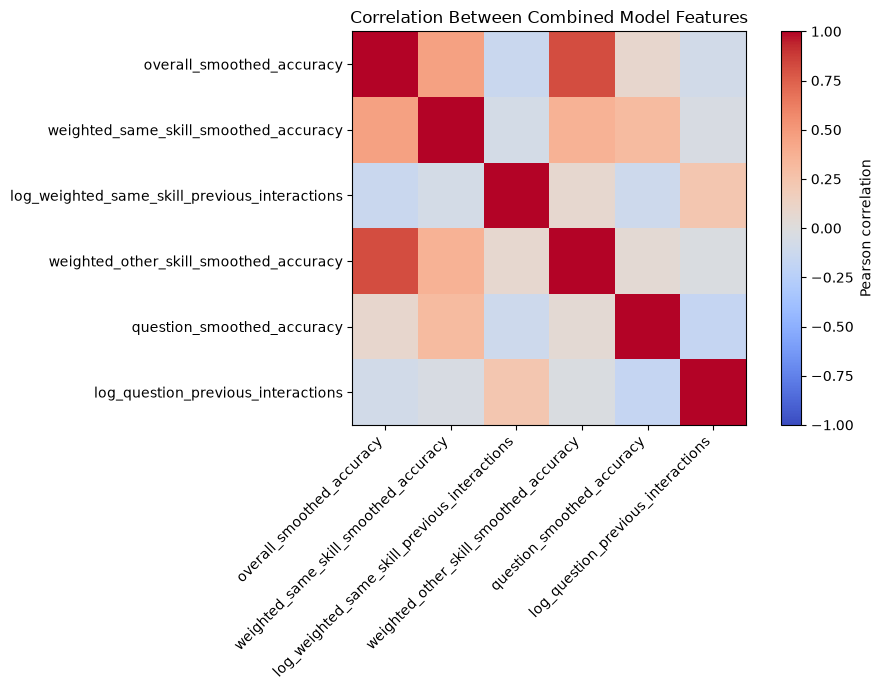

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Pearson correlation")

plt.xticks(
    range(len(correlation_features)),
    correlation_features,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_features)),
    correlation_features
)

plt.title("Correlation Between Combined Model Features")
plt.tight_layout()
plt.show()

In [15]:
experiments = {
    "without_G3": [
        feature for feature in numeric_features
        if feature != "weighted_other_skill_smoothed_accuracy"
    ] + categorical_features,

    "without_G1": [
        feature for feature in numeric_features
        if feature != "overall_smoothed_accuracy"
    ] + categorical_features
}

for name, features in experiments.items():
    print(f"{name}: {len(features)} features")
    print(features)

without_G3: 6 features
['overall_smoothed_accuracy', 'weighted_same_skill_smoothed_accuracy', 'log_weighted_same_skill_previous_interactions', 'question_smoothed_accuracy', 'log_question_previous_interactions', 'answer_type']
without_G1: 6 features
['weighted_same_skill_smoothed_accuracy', 'log_weighted_same_skill_previous_interactions', 'weighted_other_skill_smoothed_accuracy', 'question_smoothed_accuracy', 'log_question_previous_interactions', 'answer_type']


In [16]:
ablation_results = {}
ablation_predictions = {}

for experiment_name, features in experiments.items():

    print(f"\n{'='*50}")
    print(f"Experiment: {experiment_name}")
    print(f"{'='*50}")

    numerical = [
        feature for feature in features
        if feature in numeric_features
    ]

    categorical = [
        feature for feature in features
        if feature in categorical_features
    ]

    experiment_preprocessor = ColumnTransformer(
        transformers=[
            ("numerical", StandardScaler(), numerical),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical
            )
        ]
    )

    experiment_model = Pipeline(
        steps=[
            ("preprocessor", experiment_preprocessor),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    l1_ratio=0.0,
                    max_iter=1000,
                    random_state=42
                )
            )
        ]
    )

    fold_metrics = []
    predictions = []

    for fold, datasets in fold_datasets.items():

        train_df = datasets["train"]
        val_df = datasets["validation"]

        X_train = train_df[features]
        y_train = train_df[target_column]

        X_val = val_df[features]
        y_val = val_df[target_column]

        experiment_model.fit(X_train, y_train)

        y_pred = experiment_model.predict_proba(X_val)[:, 1]

        fold_metrics.append({
            "fold": fold,
            "log_loss": log_loss(y_val, y_pred),
            "brier_score": brier_score_loss(y_val, y_pred),
            "roc_auc": roc_auc_score(y_val, y_pred)
        })

        predictions.append(pd.DataFrame({
            "user_id": val_df["user_id"].values,
            "order_id": val_df["order_id"].values,
            "fold": fold,
            "y_true": y_val.values,
            "y_pred_proba": y_pred
        }))

    metrics_df = pd.DataFrame(fold_metrics)
    predictions_df = pd.concat(predictions, ignore_index=True)

    ablation_results[experiment_name] = metrics_df
    ablation_predictions[experiment_name] = predictions_df

    print("\nFold-wise mean:")
    print(metrics_df[["log_loss", "brier_score", "roc_auc"]].mean())

    print("\nPooled OOF metrics:")
    print("Log Loss:", log_loss(
        predictions_df["y_true"],
        predictions_df["y_pred_proba"]
    ))
    print("Brier Score:", brier_score_loss(
        predictions_df["y_true"],
        predictions_df["y_pred_proba"]
    ))
    print("ROC-AUC:", roc_auc_score(
        predictions_df["y_true"],
        predictions_df["y_pred_proba"]
    ))


Experiment: without_G3

Fold-wise mean:
log_loss       0.557084
brier_score    0.187777
roc_auc        0.735384
dtype: float64

Pooled OOF metrics:
Log Loss: 0.5574277782420353
Brier Score: 0.1879296744109476
ROC-AUC: 0.7355888085390301

Experiment: without_G1

Fold-wise mean:
log_loss       0.570086
brier_score    0.193504
roc_auc        0.718739
dtype: float64

Pooled OOF metrics:
Log Loss: 0.5703990151345688
Brier Score: 0.1936423349743748
ROC-AUC: 0.7189624176600476


In [17]:
experiments_additional = {
    "without_G2": [
        feature for feature in feature_columns
        if feature not in [
            "weighted_same_skill_smoothed_accuracy",
            "log_weighted_same_skill_previous_interactions"
        ]
    ],

    "without_G4": [
        feature for feature in feature_columns
        if feature not in [
            "question_smoothed_accuracy",
            "log_question_previous_interactions",
            "answer_type"
        ]
    ]
}

for name, features in experiments_additional.items():
    print(f"\n{name}: {len(features)} features")
    print(features)


without_G2: 5 features
['overall_smoothed_accuracy', 'weighted_other_skill_smoothed_accuracy', 'question_smoothed_accuracy', 'log_question_previous_interactions', 'answer_type']

without_G4: 4 features
['overall_smoothed_accuracy', 'weighted_same_skill_smoothed_accuracy', 'log_weighted_same_skill_previous_interactions', 'weighted_other_skill_smoothed_accuracy']


In [18]:
for experiment_name, features in experiments_additional.items():

    print(f"\n{'='*50}")
    print(f"Experiment: {experiment_name}")
    print(f"{'='*50}")

    numerical = [
        feature for feature in features
        if feature in numeric_features
    ]

    categorical = [
        feature for feature in features
        if feature in categorical_features
    ]

    experiment_preprocessor = ColumnTransformer(
        transformers=[
            ("numerical", StandardScaler(), numerical),
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical
            )
        ]
    )

    experiment_model = Pipeline(
        steps=[
            ("preprocessor", experiment_preprocessor),
            (
                "classifier",
                LogisticRegression(
                    C=1.0,
                    l1_ratio=0.0,
                    max_iter=1000,
                    random_state=42
                )
            )
        ]
    )

    fold_metrics = []
    predictions = []

    for fold, datasets in fold_datasets.items():

        train_df = datasets["train"]
        val_df = datasets["validation"]

        X_train = train_df[features]
        y_train = train_df[target_column]

        X_val = val_df[features]
        y_val = val_df[target_column]

        experiment_model.fit(X_train, y_train)

        y_pred = experiment_model.predict_proba(X_val)[:, 1]

        fold_metrics.append({
            "fold": fold,
            "log_loss": log_loss(y_val, y_pred),
            "brier_score": brier_score_loss(y_val, y_pred),
            "roc_auc": roc_auc_score(y_val, y_pred)
        })

        predictions.append(pd.DataFrame({
            "user_id": val_df["user_id"].values,
            "order_id": val_df["order_id"].values,
            "fold": fold,
            "y_true": y_val.values,
            "y_pred_proba": y_pred
        }))

    metrics_df = pd.DataFrame(fold_metrics)
    predictions_df = pd.concat(predictions, ignore_index=True)

    ablation_results[experiment_name] = metrics_df
    ablation_predictions[experiment_name] = predictions_df

    print("\nFold-wise mean:")
    print(
        metrics_df[
            ["log_loss", "brier_score", "roc_auc"]
        ].mean()
    )

    print("\nPooled OOF metrics:")
    print("Log Loss:", log_loss(
        predictions_df["y_true"],
        predictions_df["y_pred_proba"]
    ))

    print("Brier Score:", brier_score_loss(
        predictions_df["y_true"],
        predictions_df["y_pred_proba"]
    ))

    print("ROC-AUC:", roc_auc_score(
        predictions_df["y_true"],
        predictions_df["y_pred_proba"]
    ))


Experiment: without_G2

Fold-wise mean:
log_loss       0.568307
brier_score    0.192495
roc_auc        0.718340
dtype: float64

Pooled OOF metrics:
Log Loss: 0.5686755868188763
Brier Score: 0.19265922582421227
ROC-AUC: 0.7185568981617305

Experiment: without_G4

Fold-wise mean:
log_loss       0.568487
brier_score    0.192247
roc_auc        0.718239
dtype: float64

Pooled OOF metrics:
Log Loss: 0.5687643295893234
Brier Score: 0.1923773163764215
ROC-AUC: 0.7186909212738741


In [19]:
ablation_summary = []

# Original full model
ablation_summary.append({
    "model": "Full model",
    "log_loss": log_loss(
        oof_df["y_true"], oof_df["y_pred_proba"]
    ),
    "brier_score": brier_score_loss(
        oof_df["y_true"], oof_df["y_pred_proba"]
    ),
    "roc_auc": roc_auc_score(
        oof_df["y_true"], oof_df["y_pred_proba"]
    )
})

# Four reduced models
for name, predictions in ablation_predictions.items():

    ablation_summary.append({
        "model": name,
        "log_loss": log_loss(
            predictions["y_true"],
            predictions["y_pred_proba"]
        ),
        "brier_score": brier_score_loss(
            predictions["y_true"],
            predictions["y_pred_proba"]
        ),
        "roc_auc": roc_auc_score(
            predictions["y_true"],
            predictions["y_pred_proba"]
        )
    })

ablation_summary_df = pd.DataFrame(ablation_summary)

display(ablation_summary_df)

# Save the summary
ablation_path = prediction_dir / "combined_model_ablation_summary.csv"

ablation_summary_df.to_csv(ablation_path, index=False)

print("Saved:", ablation_path)

,model,log_loss,brier_score,roc_auc
0,Full model,0.554854,0.186792,0.739631
1,without_G3,0.557428,0.187930,0.735589
2,without_G1,0.570399,0.193642,0.718962
3,without_G2,0.568676,0.192659,0.718557
4,without_G4,0.568764,0.192377,0.718691


Saved: ..\..\..\data\processed\model_predictions\combined_model_ablation_summary.csv
